## H2: Criterio de aceptación

H2 se confirma si:
1. La proporción `Accident / (Accident + Mechanical issue)` supera el 50% en la media de 2020-2023
2. Esto ocurre en al menos 3 de las 4 temporadas (2020, 2021, 2022, 2023)
3. Esa proporción media es superior a la de 1990-1999

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

C:\Users\borja\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
C:\Users\borja\AppData\Roaming\Python\Python313\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
c:\Users\borja\anaconda3\Lib\site-packages\seaborn\_statistics.py:32: UserWarning: A NumPy version >=1.23.5 and <2.5.0 is required for this version of SciPy (detected version 2.5.4)
  from scipy.stats import gaussian_kde


In [2]:
results = pd.read_csv('../data/results_90_23.csv')
races = pd.read_csv('../data/races_90_23.csv')

# Merge con año y filtrar coches que salieron
# DNQ, DNPQ, 107% Rule, Withdrew
excluir = [81, 97, 77, 54]

results_90_23 = results[~results['statusId'].isin(excluir)].merge(
    races[['raceId', 'year']], on='raceId'
)

stats_90_23 = pd.crosstab(
    index=results_90_23['year'],
    columns=results_90_23['statusGeneric'],
    normalize='index'
) * 100

# stats_90_23 = results_90_23.groupby('year')['statusGeneric'].value_counts(normalize=True).unstack().fillna(0) * 100
stats_90_23.info()

<class 'pandas.DataFrame'>
Index: 34 entries, 1990 to 2023
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Accident          34 non-null     float64
 1   Finished          34 non-null     float64
 2   Mechanical issue  34 non-null     float64
 3   Other             34 non-null     float64
 4   Retired           34 non-null     float64
dtypes: float64(5)
memory usage: 1.6 KB


In [3]:
accidentes_90_23 = stats_90_23['Accident']
accidentes_90_23.info()

<class 'pandas.Series'>
Index: 34 entries, 1990 to 2023
Series name: Accident
Non-Null Count  Dtype  
--------------  -----  
34 non-null     float64
dtypes: float64(1)
memory usage: 544.0 bytes


In [4]:
mecanicos_90_23 = stats_90_23['Mechanical issue']
mecanicos_90_23.info()

<class 'pandas.Series'>
Index: 34 entries, 1990 to 2023
Series name: Mechanical issue
Non-Null Count  Dtype  
--------------  -----  
34 non-null     float64
dtypes: float64(1)
memory usage: 544.0 bytes


In [5]:
# Comparar por décadas
print("=== EVOLUCIÓN ACCIDENTES VS MECÁNICOS ===")
for decade, end_label in [(1990, 1999), (2000, 2009), (2010, 2019), (2020, 2023)]:
    start, end = decade, end_label
    acc_mean = accidentes_90_23.loc[start:end].mean()
    mec_mean = mecanicos_90_23.loc[start:end].mean()
    print(f"{start}-{end}: Accidentes {acc_mean:.1f}% | Mecánicos {mec_mean:.1f}%")

=== EVOLUCIÓN ACCIDENTES VS MECÁNICOS ===
1990-1999: Accidentes 17.8% | Mecánicos 30.2%
2000-2009: Accidentes 11.7% | Mecánicos 18.9%
2010-2019: Accidentes 7.6% | Mecánicos 10.5%
2020-2023: Accidentes 7.6% | Mecánicos 7.0%


In [6]:
# 7. Calcular cuota: Accident / (Accident + Mechanical issue)
cuota_accidentes = accidentes_90_23 / (accidentes_90_23 + mecanicos_90_23)

print("=== CUOTA ACCIDENTES (A/(A+M)) POR AÑO ===")
print(cuota_accidentes.round(3))

print("\n=== MEDIA DE CUOTA POR DÉCADA ===")
for start, end in [(1990, 1999), (2000, 2009), (2010, 2019), (2020, 2023)]:
    media = cuota_accidentes.loc[start:end].mean()
    print(f"{start}-{end}: Cuota media = {media:.2%}")

=== CUOTA ACCIDENTES (A/(A+M)) POR AÑO ===
year
1990    0.282
1991    0.257
1992    0.361
1993    0.426
1994    0.429
1995    0.392
1996    0.440
1997    0.415
1998    0.389
1999    0.317
2000    0.383
2001    0.297
2002    0.270
2003    0.264
2004    0.379
2005    0.438
2006    0.415
2007    0.464
2008    0.593
2009    0.547
2010    0.409
2011    0.431
2012    0.585
2013    0.467
2014    0.320
2015    0.354
2016    0.403
2017    0.379
2018    0.425
2019    0.473
2020    0.481
2021    0.574
2022    0.479
2023    0.569
dtype: float64

=== MEDIA DE CUOTA POR DÉCADA ===
1990-1999: Cuota media = 37.09%
2000-2009: Cuota media = 40.48%
2010-2019: Cuota media = 42.45%
2020-2023: Cuota media = 52.60%


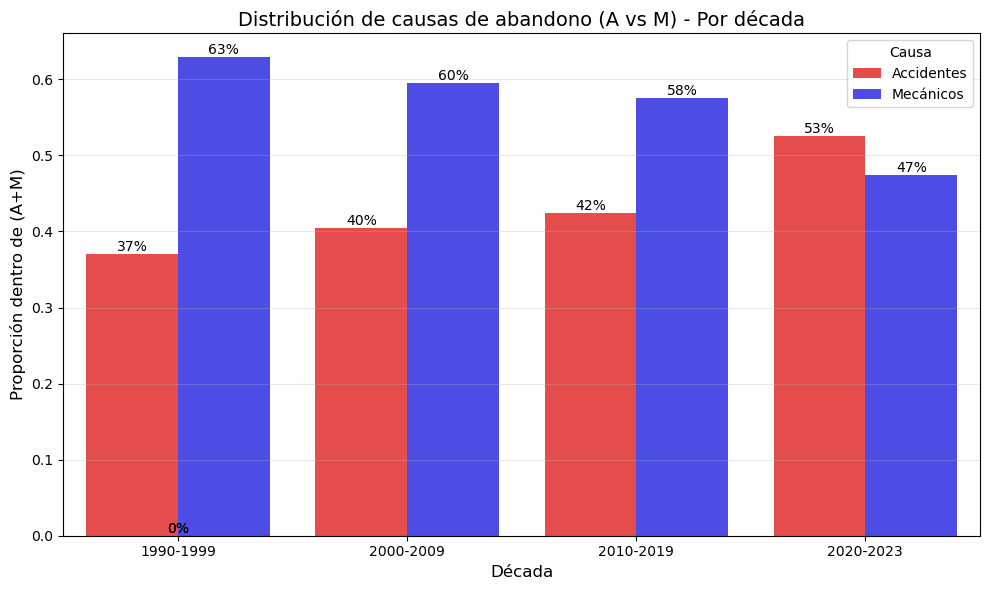

In [7]:
# Calcular cuota de mecánicos (complementaria)
cuota_mecanicos = 1 - cuota_accidentes

# Medias por década (reutilizando el bucle de celda 7)
decadas_rango = [(1990, 1999), (2000, 2009), (2010, 2019), (2020, 2023)]
etiquetas = ['1990-1999', '2000-2009', '2010-2019', '2020-2023']

acc_media = [cuota_accidentes.loc[start:end].mean() for start, end in decadas_rango]
mec_media = [cuota_mecanicos.loc[start:end].mean() for start, end in decadas_rango]

# DataFrame para seaborn
df_plot = pd.DataFrame({
    'Década': etiquetas * 2,
    'Causa': ['Accidentes'] * 4 + ['Mecánicos'] * 4,
    'Proporción': acc_media + mec_media
})

# Gráfica
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=df_plot,
    x='Década',
    y='Proporción',
    hue='Causa',
    palette={'Accidentes': 'red', 'Mecánicos': 'blue'},
    alpha=0.8
)

# Valores en barras
for p in ax.patches:
    ax.annotate(
        f'{p.get_height():.0%}',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='center', xytext=(0, 5),
        textcoords='offset points', fontsize=10
    )

plt.title('Distribución de causas de abandono (A vs M) - Por década', fontsize=14)
plt.xlabel('Década', fontsize=12)
plt.ylabel('Proporción dentro de (A+M)', fontsize=12)
plt.legend(title='Causa')
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
# 8. Verificar criterio 2: al menos 3 de 4 temporadas > 50%

años_2020s = [2020, 2021, 2022, 2023]
cuotas_2020s = cuota_accidentes.loc[años_2020s]

print("=== CUOTA POR TEMPORADA (2020-2023) ===")
for año in años_2020s:
    valor = cuotas_2020s[año]
    print(f"{año}: {valor:.1%}")

superan_50 = (cuotas_2020s > 0.5).sum()
print(f"\nTemporadas que superan 50%: {superan_50}/4")

if superan_50 >= 3:
    print("CRITERIO 2: CUMPLE")
else:
    print("CRITERIO 2: NO CUMPLE")

=== CUOTA POR TEMPORADA (2020-2023) ===
2020: 48.1%
2021: 57.4%
2022: 47.9%
2023: 56.9%

Temporadas que superan 50%: 2/4
CRITERIO 2: NO CUMPLE


In [9]:
# Escenario: Todas las Suspension (statusId 22) como Accident
results_sin_susp = results_90_23.copy()
results_sin_susp.loc[results_sin_susp['statusId'] == 22, 'statusGeneric'] = 'Accident'

# Recalcular todo
stats_sin_susp = pd.crosstab(index=results_sin_susp['year'], columns=results_sin_susp['statusGeneric'], normalize='index') * 100
acc_sin_susp = stats_sin_susp['Accident']
mec_sin_susp = stats_sin_susp['Mechanical issue']
cuota_sin_susp = acc_sin_susp / (acc_sin_susp + mec_sin_susp)

# Verificar criterios
print("=== SENSIBILIDAD: Suspension como Accident ===")
for año in [2020, 2021, 2022, 2023]:
    print(f"{año}: {cuota_sin_susp[año]:.1%}")

=== SENSIBILIDAD: Suspension como Accident ===
2020: 50.0%
2021: 61.1%
2022: 49.3%
2023: 56.9%


In [10]:
# 10. Conclusión H2 con sensibilidad

# Media 2020-2023 en escenario de sensibilidad
media_2020s_sin_susp = cuota_sin_susp.loc[2020:2023].mean()

# Media 1990-1999 en escenario de sensibilidad
media_1990s_sin_susp = cuota_sin_susp.loc[1990:1999].mean()

print("=== CONCLUSIÓN H2 (Sensibilidad: Suspension como Accident) ===")
print(f"Media 2020-2023: {media_2020s_sin_susp:.2%}")
print(f"Media 1990-1999: {media_1990s_sin_susp:.2%}")

# Verificar los 3 criterios
c1 = media_2020s_sin_susp > 0.5
c2 = (cuota_sin_susp.loc[[2020,2021,2022,2023]] > 0.5).sum() >= 3
c3 = media_2020s_sin_susp > media_1990s_sin_susp

print(f"\nCriterio 1 (Media > 50%): {'CUMPLE' if c1 else 'NO CUMPLE'}")
print(f"Criterio 2 (3/4 temporadas): {'CUMPLE' if c2 else 'NO CUMPLE'}")
print(f"Criterio 3 (Mayor que 1990s): {'CUMPLE' if c3 else 'NO CUMPLE'}")

if c1 and c2 and c3:
    print("\nH2 SE CONFIRMA bajo el escenario de sensibilidad")
else:
    print("\nH2 NO se confirma")

=== CONCLUSIÓN H2 (Sensibilidad: Suspension como Accident) ===
Media 2020-2023: 54.33%
Media 1990-1999: 40.24%

Criterio 1 (Media > 50%): CUMPLE
Criterio 2 (3/4 temporadas): NO CUMPLE
Criterio 3 (Mayor que 1990s): CUMPLE

H2 NO se confirma


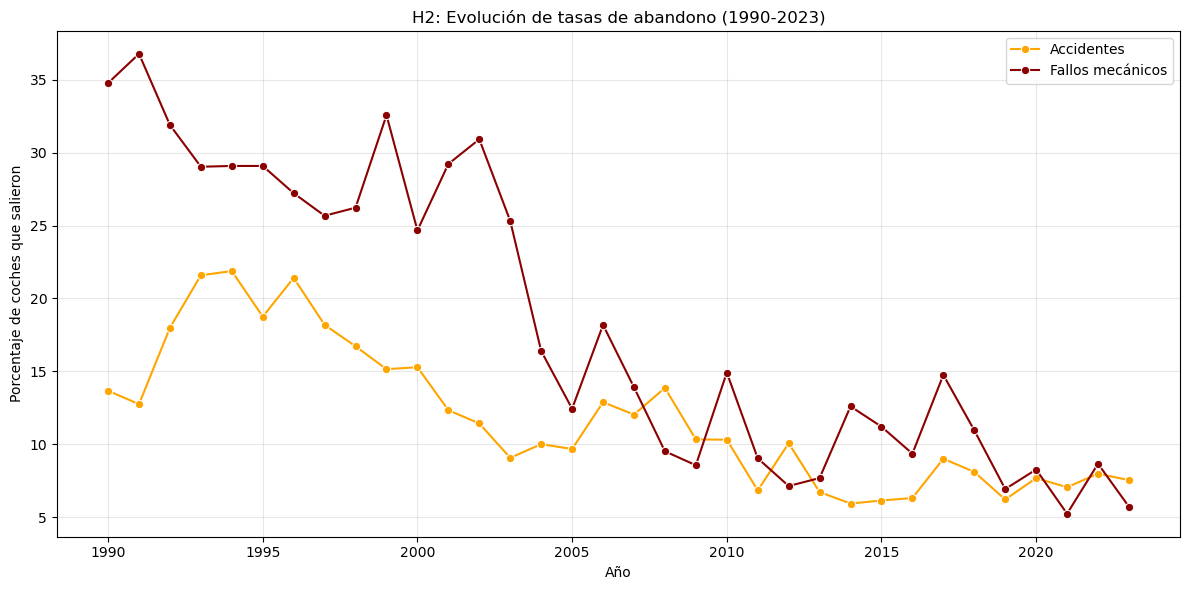

In [11]:
plt.figure(figsize=(12, 6))

# Trazar accidentes (naranja)
sns.lineplot(
    data=accidentes_90_23,
    marker='o',
    markersize=6,
    color='orange',
    label='Accidentes'
)

# Trazar mecánicos (rojo oscuro)
sns.lineplot(
    data=mecanicos_90_23,
    marker='o',
    markersize=6,
    color='darkred',
    label='Fallos mecánicos'
)

plt.title('H2: Evolución de tasas de abandono (1990-2023)')
plt.xlabel('Año')
plt.ylabel('Porcentaje de coches que salieron')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Utilizar esta gráfica para la presentacion

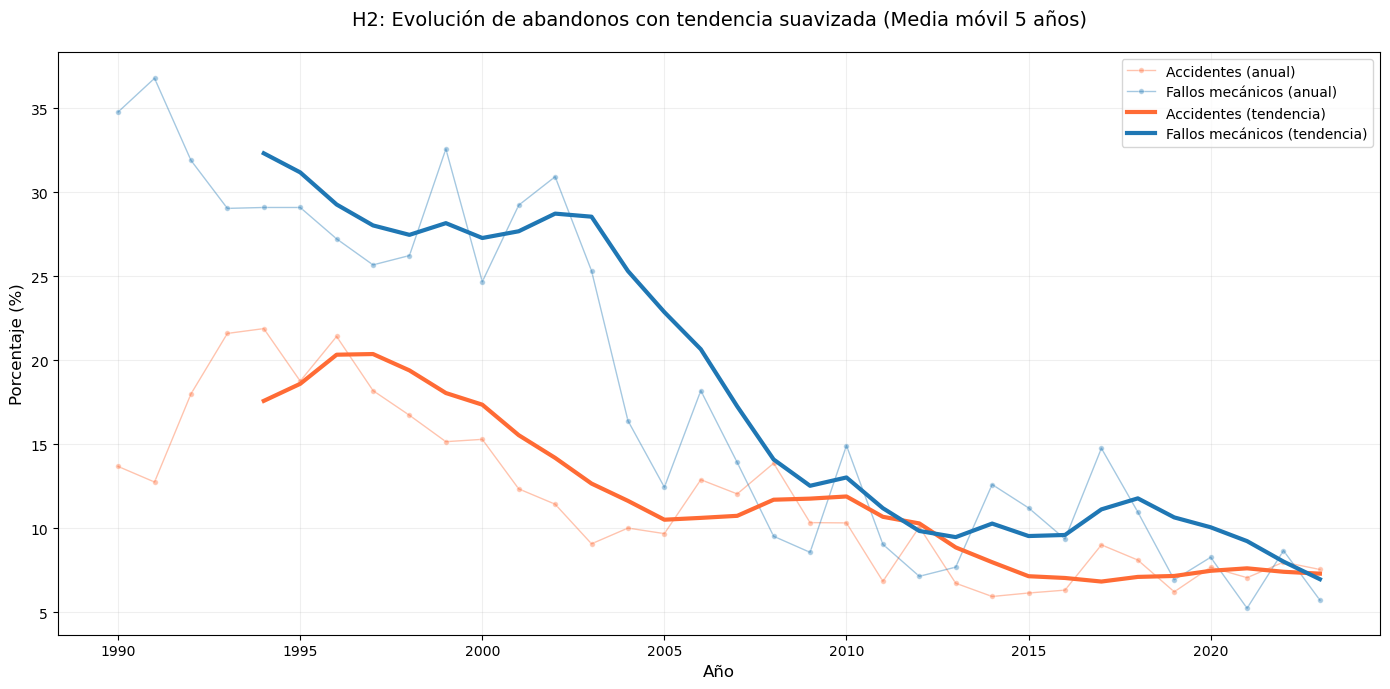

In [12]:
# Media móvil de 5 años para suavizar
window = 5
acc_mm = accidentes_90_23.rolling(window=window).mean()
mec_mm = mecanicos_90_23.rolling(window=window).mean()

plt.figure(figsize=(14, 7))

# Datos reales (transparentes)
sns.lineplot(
    data=accidentes_90_23,
    marker='o',
    markersize=4,
    color='#FF6B35',
    label='Accidentes (anual)',
    linewidth=1,
    alpha=0.4
)
sns.lineplot(
    data=mecanicos_90_23,
    marker='o',
    markersize=4,
    color='#1F77B4',
    label='Fallos mecánicos (anual)',
    linewidth=1,
    alpha=0.4
)

# Media móvil (destacada)
sns.lineplot(
    data=acc_mm,
    color='#FF6B35',
    label='Accidentes (tendencia)',
    linewidth=3
)
sns.lineplot(
    data=mec_mm,
    color='#1F77B4',
    label='Fallos mecánicos (tendencia)',
    linewidth=3
)

plt.title(
    'H2: Evolución de abandonos con tendencia suavizada (Media móvil 5 años)',
    fontsize=14,
    pad=20
)
plt.xlabel('Año', fontsize=12)
plt.ylabel('Porcentaje (%)', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

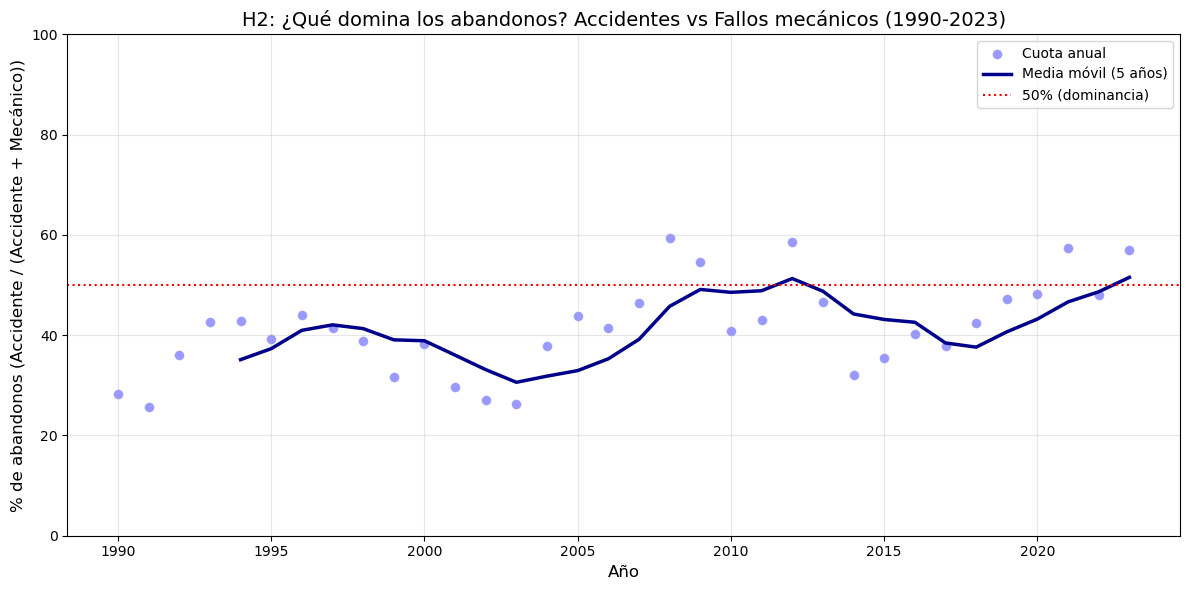

In [45]:
# --- Gráfico de media móvil de A/(A+M) ---

# 1. Calcular cuota A/(A+M) por año
cuota_am = (accidentes_90_23 / (accidentes_90_23 + mecanicos_90_23)) * 100

# 2. Gráfico de media móvil
plt.figure(figsize=(12, 6))
sns.scatterplot(x=cuota_am.index, y=cuota_am, color='blue', alpha=0.4, s=50, label='Cuota anual')
sns.lineplot(data=cuota_am.rolling(window=5).mean(), color='darkblue', linewidth=2.5, label='Media móvil (5 años)')
plt.axhline(y=50, color='red', linestyle=':', linewidth=1.5, label='50% (dominancia)')
plt.title('H2: ¿Qué domina los abandonos? Accidentes vs Fallos mecánicos (1990-2023)', fontsize=14)
plt.xlabel('Año', fontsize=12)
plt.ylabel('% de abandonos (Accidente / (Accidente + Mecánico))', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## 📌 CONCLUSIÓN H2: "Los accidentes, no los fallos, dominan ya los abandonos (1990-2023)"

### Criterio de aceptación definido (a priori):
H2 se confirma si:
1. La proporción `Accident / (Accident + Mechanical issue)` supera el 50% en la media de 2020-2023
2. Esto ocurre en **al menos 3 de las 4 temporadas** (2020, 2021, 2022, 2023)
3. Esa proporción media es superior a la de 1990-1999

---

### ✅ Resultados obtenidos:

| Década | Cuota media A/(A+M) | Tasas absolutas |
|--------|---------------------|-----------------|
| 1990-1999 | **37.09%** | Acc: 17.8% | Mec: 30.2% |
| 2000-2009 | 40.48% | Acc: 11.7% | Mec: 18.9% |
| 2010-2019 | 42.45% | Acc: 7.6% | Mec: 10.5% |
| 2020-2023 | **52.60%** | Acc: 7.6% | Mec: 7.0% |

| Temporada | Cuota A/(A+M) | ¿Supera 50%? |
|-----------|----------------|--------------|
| 2020 | 48.1% | ❌ NO |
| 2021 | 57.4% | ✅ SÍ |
| 2022 | 47.9% | ❌ NO |
| 2023 | 56.9% | ✅ SÍ |

---

### ✅ Verificación de criterios:
1. **Media 2020-2023 > 50%**: ✅ **52.60% > 50%** (CUMPLE)
2. **3/4 temporadas > 50%**: ❌ **Solo 2 de 4** (2021 y 2023) (NO CUMPLE)
3. **Media 2020-2023 > Media 1990-1999**: ✅ **52.60% > 37.09%** (CUMPLE)

---

### 🎯 **CONCLUSIÓN FINAL:**
**H2 NO SE CONFIRMA** bajo el criterio definido.

El criterio 2 (3 de 4 temporadas con cuota > 50%) **no se cumple** porque 2020 (48.1%) y 2022 (47.9%) están ligeramente por debajo del umbral, a pesar de que la media de la década sí supera el 50%.

---

### 🔬 Análisis de sensibilidad:
Si clasificamos `Suspension` (statusId 22) como **Accident** (142 casos con ambigüedad en la auditoría):
- Media 2020-2023: **54.33%** ✅
- Media 1990-1999: **40.24%** ✅
- Temporadas > 50%: **2/4** ❌ (sigue sin cumplir el criterio 2)

**H2 sigue sin confirmarse** incluso bajo este escenario de sensibilidad.

---

### 💡 Interpretación:
Aunque los accidentes han ganado peso relativo (de 37% a 53% de las causas de abandono), **no dominan de forma sostenida en los últimos 4 años**. El umbral del 50% en 3 de 4 temporadas es exigente y refleja que el cambio es reciente y con fluctuaciones anuales.

**→ H2 se REFUTA con los datos actuales.**